In [1]:
import numpy as np
import matplotlib.pyplot as plt

from model_interface import *
import kinetics

In [2]:
def run_sim(
    glu_in=0.0,
    fat_in=0.0,
    atp_draw=0.0,
    steps=3000
):

    state = kinetics.DEFAULT_STATE.copy()

    history = []

    for _ in range(steps):

        state, flux = step_ivp_once(
            state,
            glu_in=glu_in,
            fat_in=fat_in,
            atp_draw=atp_draw
        )

        history.append(state.copy())

    return (
        np.array(history),
        state,
        flux
    )

In [3]:
def print_states(state):

    print("\nFINAL STATES")
    print("-" * 40)

    for name, value in zip(
        kinetics.STATE_NAMES,
        state
    ):
        print(f"{name:15s} {value:10.4f}")

In [4]:
def print_derivatives(state, inputs):

    dxdt = derivatives(
        0,
        state,
        inputs
    )

    print("\nFINAL DERIVATIVES")
    print("-" * 40)

    for name, value in zip(
        kinetics.STATE_NAMES,
        dxdt
    ):
        print(f"{name:15s} {value:10.6f}")

In [5]:
def print_fluxes(state, inputs):

    fluxes = kinetics.compute_fluxes(
        state,
        inputs
    )

    print("\nFINAL FLUXES")
    print("-" * 40)

    for name, value in fluxes.items():
        print(f"{name:15s} {value:10.6f}")

In [ ]:
inputs = {
    "glu_in": 1.0,
    "fat_in": 0.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)

In [6]:
# ------------------------------------------------------------
# Test 1 - Glucose Only
#
# Purpose:
# Verify that glucose can propagate through the entire
# glucose pathway and produce AcCoA, citrate and malonyl-CoA.
#
# Questions:
# - Do pathway intermediates accumulate?
# - Does the system approach steady state?
# - Which pool becomes the major sink?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 0.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)


FINAL STATES
----------------------------------------
Glc_ext           104.8702
Glc                 0.2359
Glc6P               0.1057
Fru6P               0.9912
Fru16P2             0.1060
Pyruvate            0.1172
AcCoA               0.2028
Cit                 4.2115
LCFA_ext            0.0000
LCFA_CoA_cyto       0.4884
LCFA_CoA_mito       0.0880
Mal                 3.0647
TAG                10.4507

FINAL DERIVATIVES
----------------------------------------
Glc_ext           0.809928
Glc              -0.000792
Glc6P            -0.000319
Fru6P             0.000074
Fru16P2          -0.000322
Pyruvate         -0.000388
AcCoA            -0.000533
Cit               0.014379
LCFA_ext          0.000000
LCFA_CoA_cyto     0.000558
LCFA_CoA_mito    -0.000171
Mal               0.010332
TAG               0.062626

FINAL FLUXES
----------------------------------------
GLUT4             0.190072
Glycolysis        0.095839
PDH               0.087191
Citrate_prod      0.168619
ACL_ACC           0.

In [ ]:
# ------------------------------------------------------------
# Test 2 - Fat Only
#
# Purpose:
# Verify fatty-acid uptake and beta oxidation.
#
# Questions:
# - Does LCFA propagate correctly?
# - Is AcCoA produced?
# - Does citrate accumulate?
# - Is CPT1 inhibition activated?
# ------------------------------------------------------------

inputs = {
    "glu_in": 0.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)

In [ ]:
# ------------------------------------------------------------
# Test 3 - Mixed Fuels
#
# Purpose:
# Test interaction between glucose and fat metabolism.
#
# Questions:
# - Does citrate inhibition appear?
# - Does malonyl-CoA accumulate?
# - Is fuel competition visible?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)

In [ ]:
# ------------------------------------------------------------
# Test 4 - ATP Demand
#
# Purpose:
# Verify ATP demand drives substrate consumption.
#
# Questions:
# - Does citrate decrease with ATP demand?
# - Does AcCoA remain bounded?
# - Is the response stable?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 0.0,
    "atp_draw": 1.0
}

history, state, flux = run_sim(**inputs)

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)

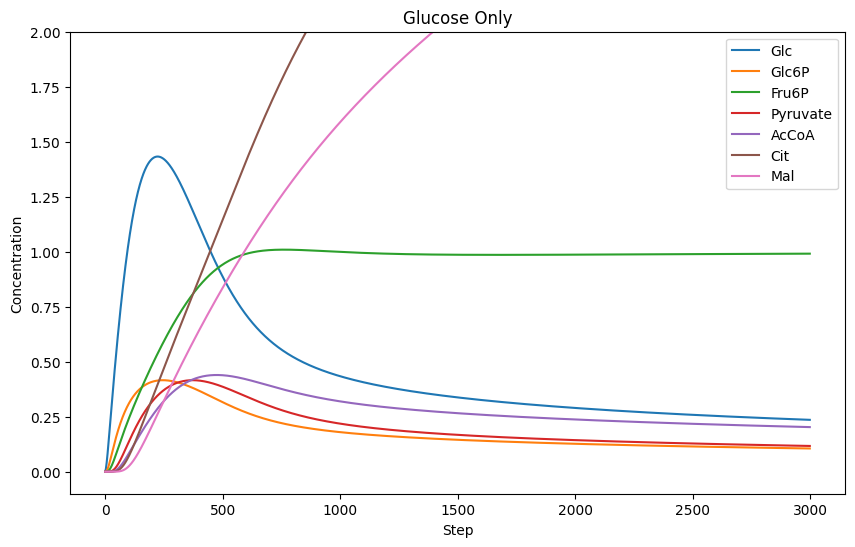

In [7]:
# ------------------------------------------------------------
# Dynamic Test 1 - Glucose Only
#
# Purpose:
# Verify propagation through the glucose pathway.
#
# Expected:
# Glc -> Pyruvate -> AcCoA -> Cit -> Mal
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 0.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(10, 6))

for metabolite in [
    "Glc",
    "Glc6P",
    "Fru6P",
    "Pyruvate",
    "AcCoA",
    "Cit",
    "Mal"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Glucose Only")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 2)
plt.legend()
plt.show()

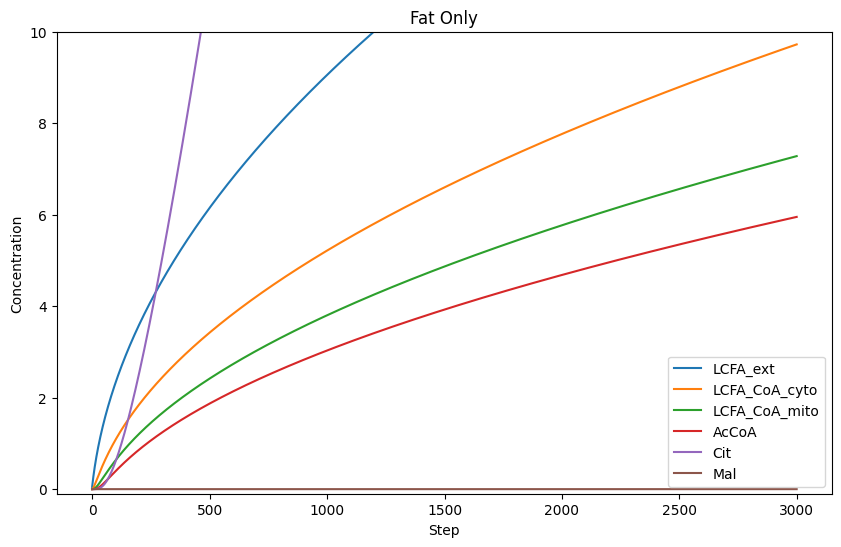

In [8]:
# ------------------------------------------------------------
# Dynamic Test 2 - Fat Only
#
# Purpose:
# Verify propagation through the fat pathway.
#
# Expected:
# LCFA -> LCFA_CoA_cyto -> LCFA_CoA_mito
# -> AcCoA -> Cit -> Mal
# ------------------------------------------------------------

inputs = {
    "glu_in": 0.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(10, 6))

for metabolite in [
    "LCFA_ext",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "AcCoA",
    "Cit",
    "Mal"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Fat Only")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 10)
plt.legend()
plt.show()

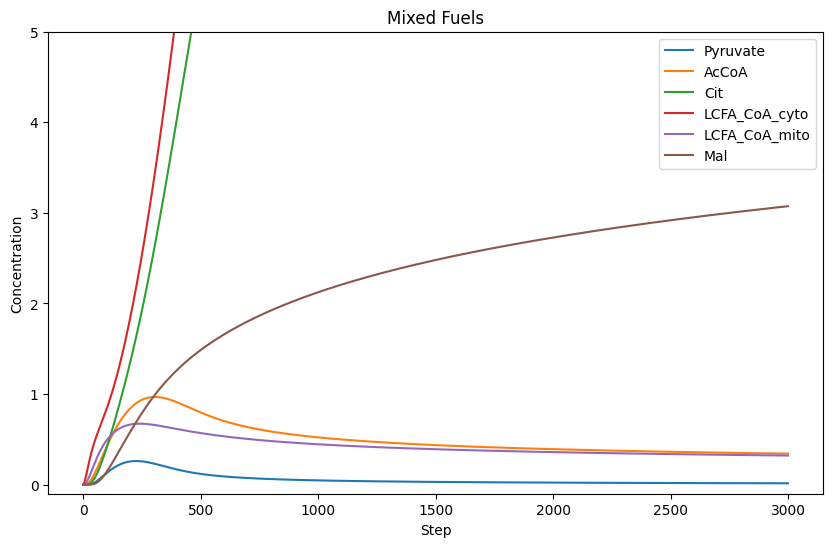

In [9]:
# ------------------------------------------------------------
# Dynamic Test 3 - Mixed Fuels
#
# Purpose:
# Observe glucose-fat interaction.
#
# Expected:
# Shared AcCoA production and citrate signalling.
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(10, 6))

for metabolite in [
    "Pyruvate",
    "AcCoA",
    "Cit",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "Mal"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Mixed Fuels")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 5)
plt.legend()
plt.show()

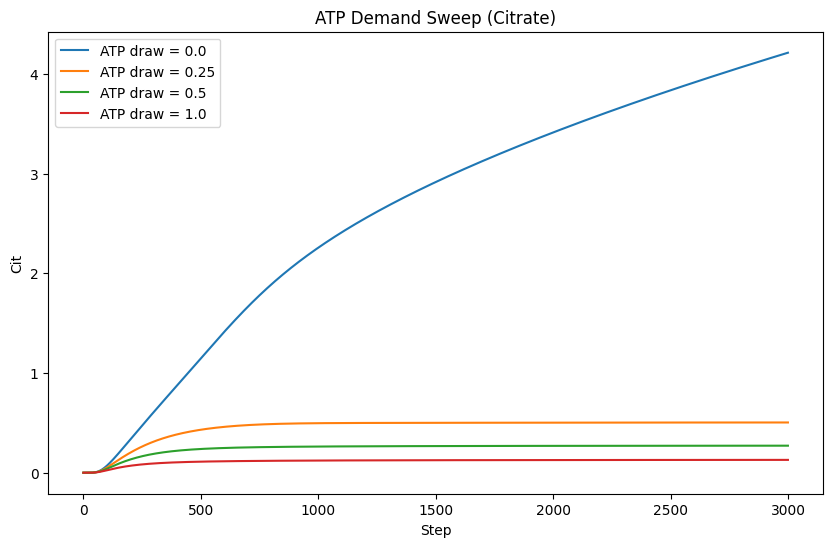

In [10]:
# ------------------------------------------------------------
# Dynamic Test 4 - ATP Demand Sweep
#
# Purpose:
# Compare citrate dynamics under different ATP demand.
#
# Expected:
# Higher ATP demand should reduce AcCoA and Cit.
# ------------------------------------------------------------

draw_values = [0.0, 0.25, 0.5, 1.0]

plt.figure(figsize=(10, 6))

for draw in draw_values:

    history, state, flux = run_sim(
        glu_in=1.0,
        fat_in=0.0,
        atp_draw=draw
    )

    plt.plot(
        history[:, kinetics.STATE_INDEX["Cit"]],
        label=f"ATP draw = {draw}"
    )

plt.title("ATP Demand Sweep (Citrate)")
plt.xlabel("Step")
plt.ylabel("Cit")
plt.legend()
plt.show()

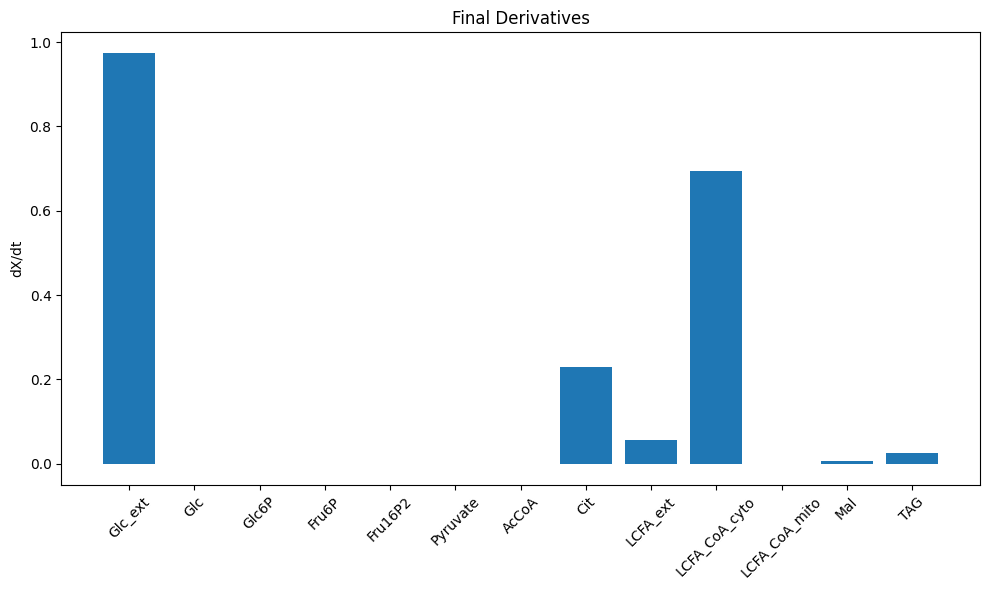

In [11]:
# ------------------------------------------------------------
# Dynamic Test 5 - Steady-State Derivatives
#
# Purpose:
# Check which pools are still accumulating.
#
# Expected:
# Values near zero indicate steady state.
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

dxdt = derivatives(0, state, inputs)

plt.figure(figsize=(10, 6))

plt.bar(
    kinetics.STATE_NAMES,
    dxdt
)

plt.xticks(rotation=45)
plt.ylabel("dX/dt")
plt.title("Final Derivatives")
plt.tight_layout()
plt.show()

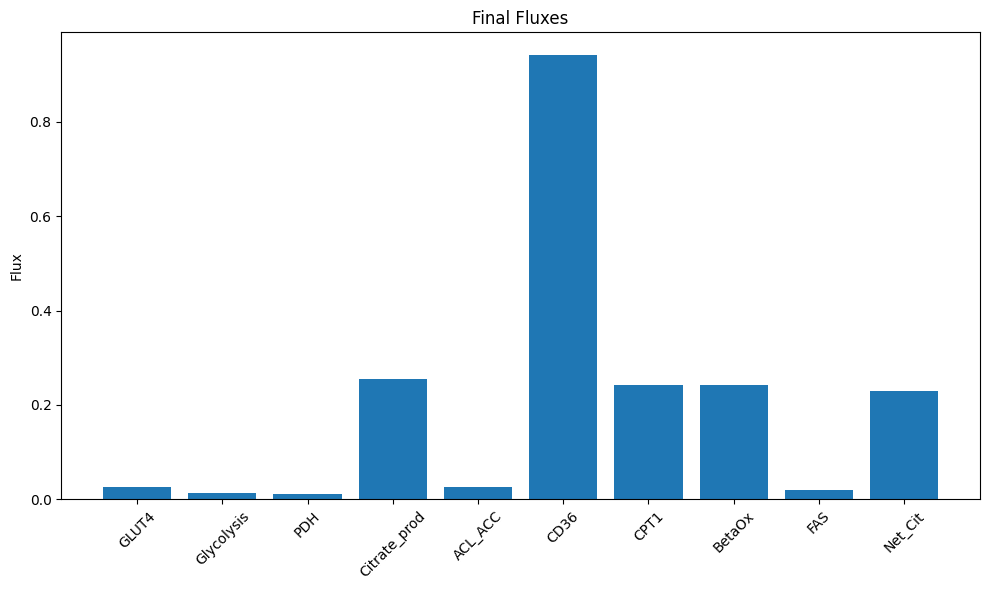

In [12]:
# ------------------------------------------------------------
# Dynamic Test 6 - Final Flux Profile
#
# Purpose:
# Identify dominant pathway fluxes.
#
# Expected:
# Bottlenecks become visible immediately.
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

fluxes = kinetics.compute_fluxes(state, inputs)

plt.figure(figsize=(10, 6))

plt.bar(
    list(fluxes.keys()),
    list(fluxes.values())
)

plt.xticks(rotation=45)
plt.ylabel("Flux")
plt.title("Final Fluxes")
plt.tight_layout()
plt.show()

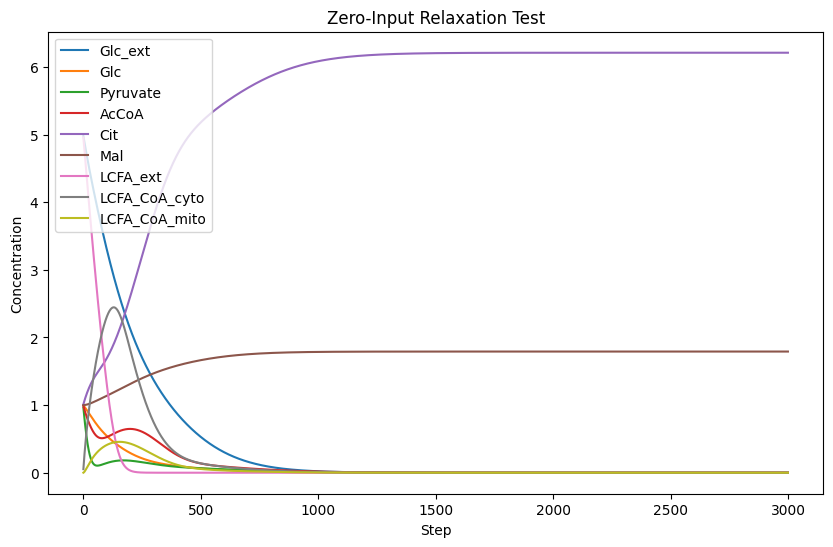


FINAL STATES
----------------------------------------
Glc_ext             0.0000
Glc                 0.0000
Glc6P               0.0000
Fru6P               0.0000
Fru16P2             0.0000
Pyruvate            0.0000
AcCoA               0.0000
Cit                 6.2119
LCFA_ext            0.0000
LCFA_CoA_cyto       0.0000
LCFA_CoA_mito       0.0000
Mal                 1.7922
TAG                 2.9190

FINAL DERIVATIVES
----------------------------------------
Glc_ext          -0.000000
Glc              -0.000000
Glc6P            -0.000000
Fru6P            -0.000000
Fru16P2          -0.000000
Pyruvate         -0.000000
AcCoA            -0.000000
Cit               0.000000
LCFA_ext         -0.000000
LCFA_CoA_cyto    -0.000000
LCFA_CoA_mito    -0.000000
Mal               0.000000
TAG               0.000000

FINAL FLUXES
----------------------------------------
GLUT4             0.000000
Glycolysis        0.000000
PDH               0.000000
Citrate_prod      0.000000
ACL_ACC           0.

In [13]:
# ------------------------------------------------------------
# Dynamic Test - Zero Input Relaxation
#
# Purpose:
# Verify that the model relaxes naturally when there is
# no external glucose, fatty-acid input, or ATP demand.
#
# Questions:
# - Do metabolite pools decay?
# - Does the system approach zero?
# - Are any hidden positive feedback loops present?
# - Is the model intrinsically stable?
#
# Inputs:
# glu_in = 0
# fat_in = 0
# atp_draw = 0
#
# Initial Condition:
# Start from a non-zero state.
# ------------------------------------------------------------

inputs = {
    "glu_in": 0.0,
    "fat_in": 0.0,
    "atp_draw": 0.0
}

state = kinetics.DEFAULT_STATE.copy()

# Seed the system with metabolites

state[kinetics.STATE_INDEX["Glc_ext"]] = 5.0
state[kinetics.STATE_INDEX["LCFA_ext"]] = 5.0
state[kinetics.STATE_INDEX["Glc"]] = 1.0
state[kinetics.STATE_INDEX["Pyruvate"]] = 1.0
state[kinetics.STATE_INDEX["AcCoA"]] = 1.0
state[kinetics.STATE_INDEX["Cit"]] = 1.0
state[kinetics.STATE_INDEX["Mal"]] = 1.0

history = []

for _ in range(3000):

    state, flux = step_ivp_once(
        state,
        **inputs
    )

    history.append(state.copy())

history = np.array(history)

plt.figure(figsize=(10, 6))

for metabolite in [
    "Glc_ext",
    "Glc",
    "Pyruvate",
    "AcCoA",
    "Cit",
    "Mal",
    "LCFA_ext",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Zero-Input Relaxation Test")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.legend()
plt.show()

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)

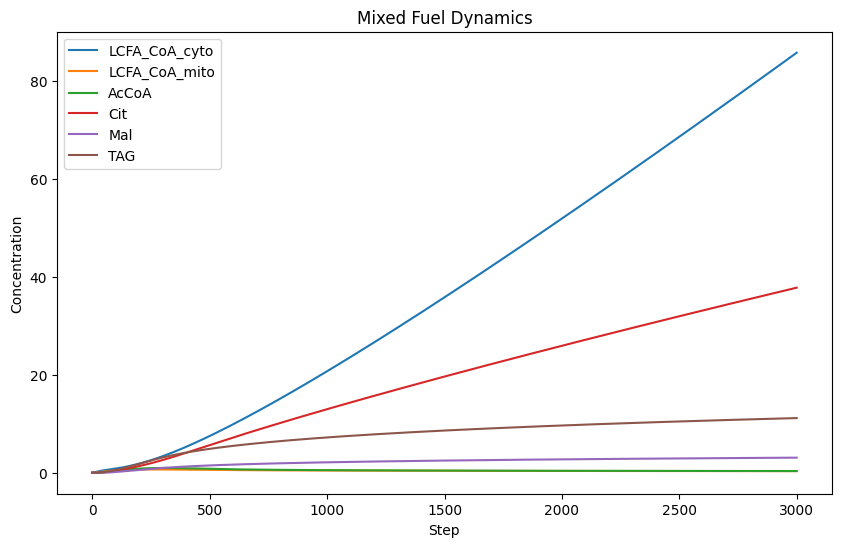

In [14]:
# ------------------------------------------------------------
# Dynamic Test - Mixed Fuels + TAG
#
# Purpose:
# Observe accumulation of storage fat (TAG)
# alongside active metabolism.
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(10, 6))

for metabolite in [
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "AcCoA",
    "Cit",
    "Mal",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Mixed Fuel Dynamics")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.legend()
plt.show()

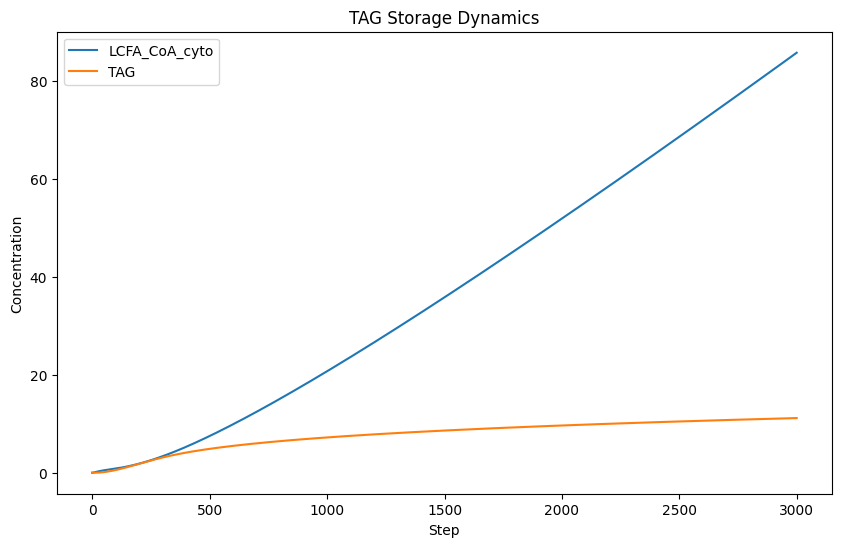

In [15]:
# ------------------------------------------------------------
# Dynamic Test - TAG Storage Dynamics
#
# Purpose:
# Observe whether carbon is being diverted into TAG storage.
#
# Questions:
# - Does TAG accumulate continuously?
# - How does TAG compare to LCFA_CoA_cyto?
# - Does TAG begin to plateau or keep increasing?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(10, 6))

for metabolite in [
    "LCFA_CoA_cyto",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("TAG Storage Dynamics")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.legend()
plt.show()

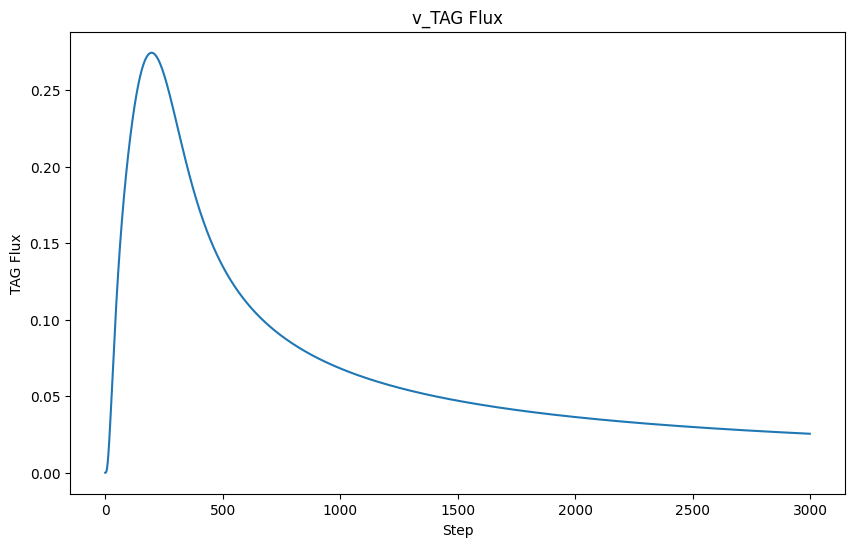

In [16]:
# ------------------------------------------------------------
# Dynamic Test - v_TAG Flux
#
# Purpose:
# Observe TAG synthesis activity over time.
#
# Questions:
# - Does TAG synthesis saturate?
# - Does TAG synthesis increase with substrate availability?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

state = kinetics.DEFAULT_STATE.copy()

tag_flux = []

for _ in range(3000):

    state, flux = step_ivp_once(
        state,
        **inputs
    )

    tag_flux.append(
        kinetics.v_TAG(
            state[kinetics.STATE_INDEX["LCFA_CoA_cyto"]],
            state[kinetics.STATE_INDEX["Glc"]]
        )
    )

plt.figure(figsize=(10, 6))

plt.plot(tag_flux)

plt.title("v_TAG Flux")
plt.xlabel("Step")
plt.ylabel("TAG Flux")
plt.show()

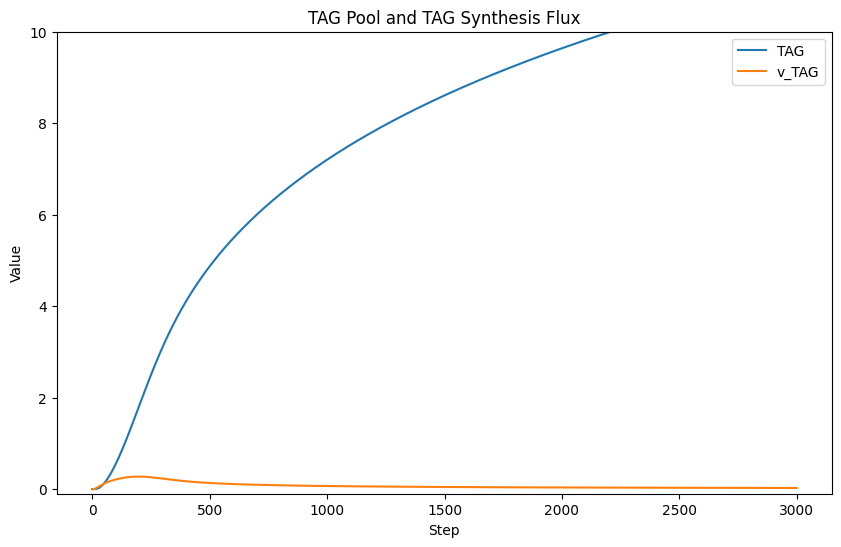

In [17]:
# ------------------------------------------------------------
# Dynamic Test - TAG Pool vs TAG Flux
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.0,
    "fat_in": 1.0,
    "atp_draw": 0.0
}

state = kinetics.DEFAULT_STATE.copy()

tag_pool = []
tag_flux = []

for _ in range(3000):

    state, flux = step_ivp_once(
        state,
        **inputs
    )

    tag_pool.append(
        state[kinetics.STATE_INDEX["TAG"]]
    )

    tag_flux.append(
        kinetics.v_TAG(
            state[kinetics.STATE_INDEX["LCFA_CoA_cyto"]],
            state[kinetics.STATE_INDEX["Glc"]]
        )
    )

plt.figure(figsize=(10, 6))

plt.plot(tag_pool, label="TAG")
plt.plot(tag_flux, label="v_TAG")

plt.title("TAG Pool and TAG Synthesis Flux")
plt.xlabel("Step")
plt.ylabel("Value")
plt.ylim(-0.1, 10)
plt.legend()
plt.show()


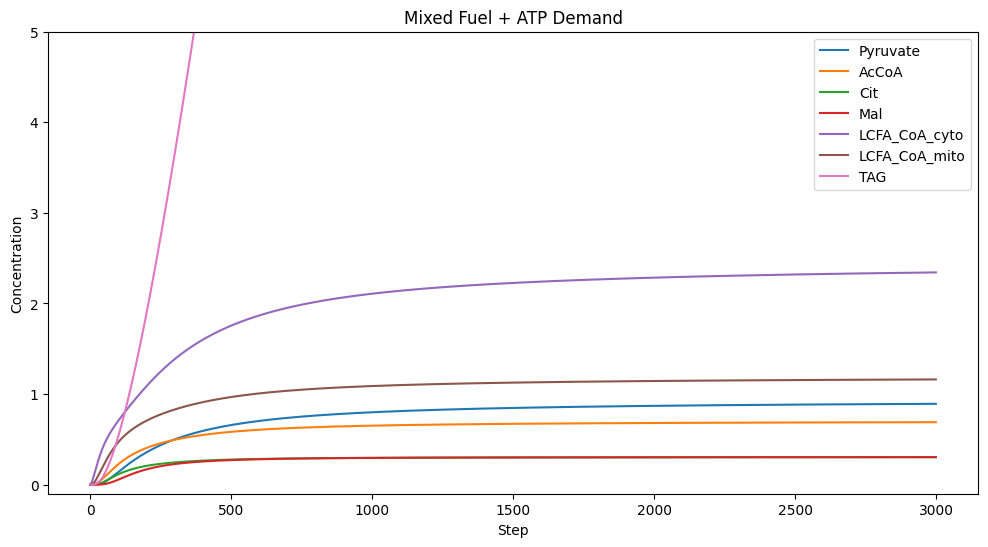


FINAL STATES
----------------------------------------
Glc_ext            55.4568
Glc                 3.0312
Glc6P               0.6023
Fru6P               0.9597
Fru16P2             0.6013
Pyruvate            0.8925
AcCoA               0.6897
Cit                 0.3037
LCFA_ext            8.1073
LCFA_CoA_cyto       2.3431
LCFA_CoA_mito       1.1616
Mal                 0.3037
TAG                71.1436

FINAL DERIVATIVES
----------------------------------------
Glc_ext           0.346567
Glc               0.001500
Glc6P             0.000121
Fru6P             0.000280
Fru16P2           0.000135
Pyruvate          0.000288
AcCoA             0.000112
Cit               0.000017
LCFA_ext          0.009802
LCFA_CoA_cyto     0.000749
LCFA_CoA_mito     0.000221
Mal               0.000018
TAG               0.527013

FINAL FLUXES
----------------------------------------
GLUT4             0.753433
Glycolysis        0.375491
PDH               0.279098
Citrate_prod      0.408184
ACL_ACC           0.

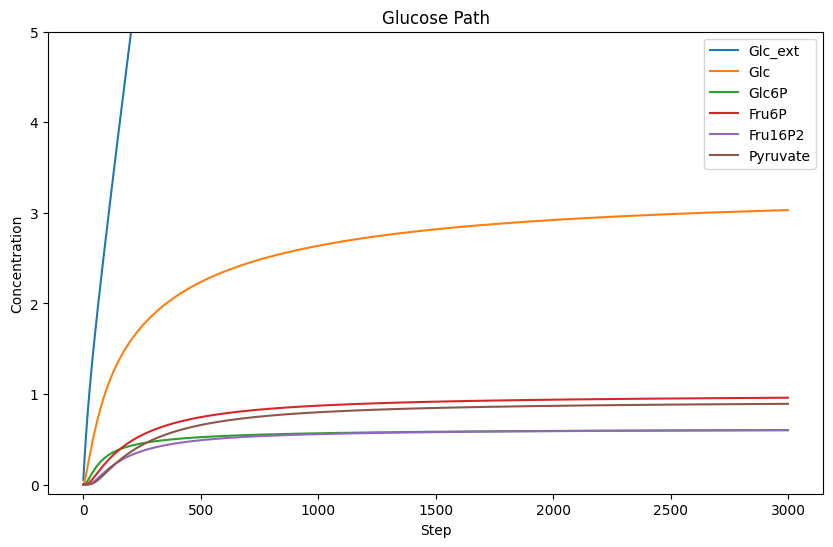

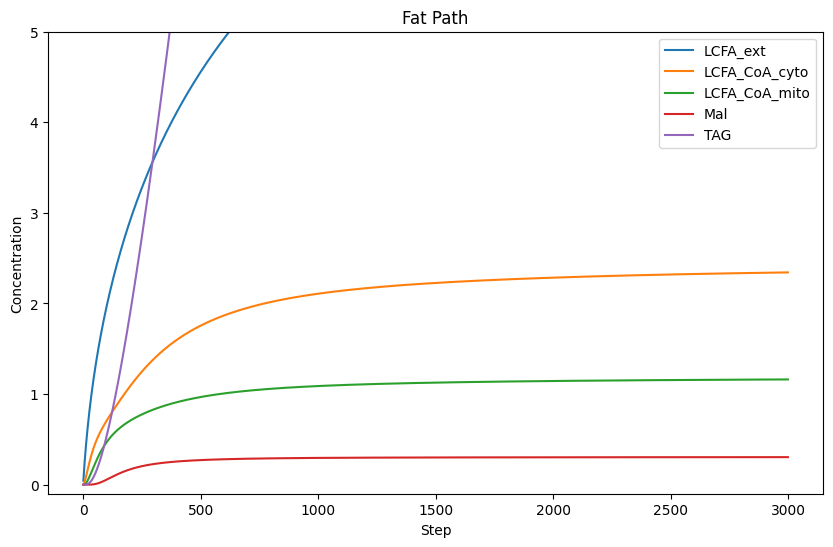

In [18]:
# ------------------------------------------------------------
# Dynamic Test - Mixed Inputs + ATP Demand
#
# Purpose:
# Run the full integrated model:
# glucose + fat + energy demand.
#
# Questions:
# - Does the system reach a quasi-steady state?
# - Does TAG continue accumulating?
# - How large are Cit and Mal pools?
# - Are glucose and fat pathways both active?
# ------------------------------------------------------------

inputs = {
    "glu_in": 1.1,
    "fat_in": 0.9,
    "atp_draw": 1.0
}

history, state, flux = run_sim(**inputs)

plt.figure(figsize=(12, 6))

for metabolite in [
    "Pyruvate",
    "AcCoA",
    "Cit",
    "Mal",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Mixed Fuel + ATP Demand")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 5)
plt.legend()
plt.show()

print_states(state)
print_derivatives(state, inputs)
print_fluxes(state, inputs)



plt.figure(figsize=(10, 6))

for metabolite in [
    "Glc_ext",
    "Glc",
    "Glc6P",
    "Fru6P",
    "Fru16P2",
    "Pyruvate"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Glucose Path")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 5)
plt.legend()
plt.show()




plt.figure(figsize=(10, 6))

for metabolite in [
    "LCFA_ext",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "Mal",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.title("Fat Path")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 5)
plt.legend()
plt.show()

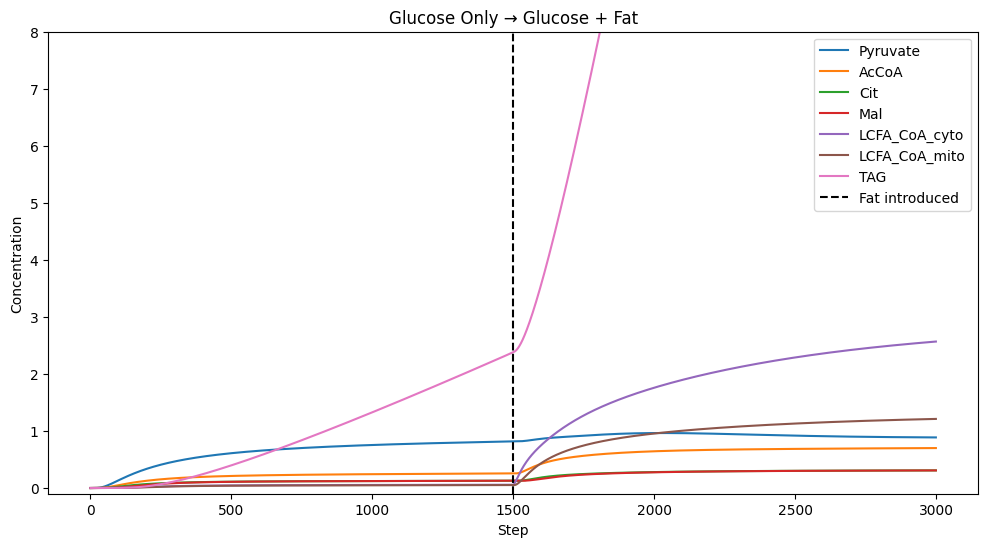

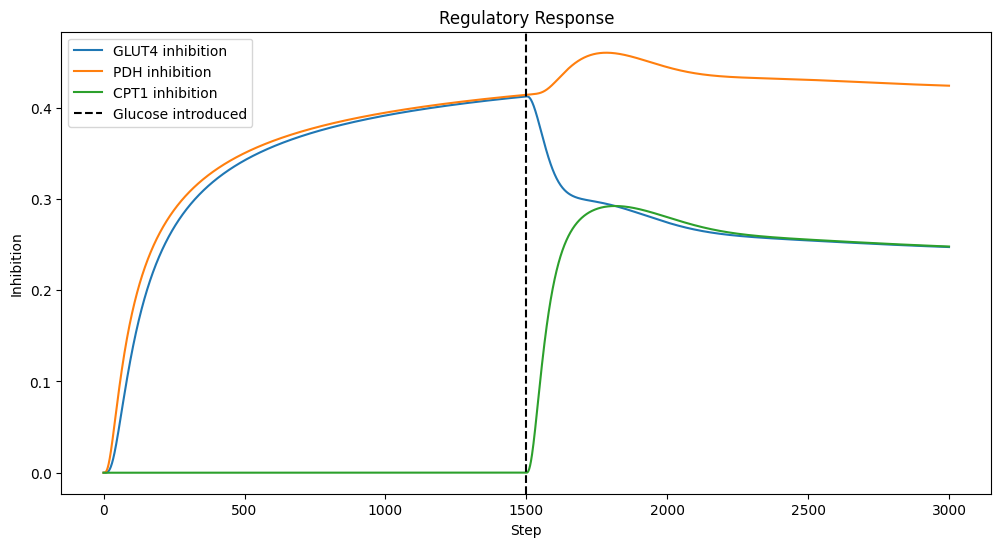

In [19]:
# ------------------------------------------------------------
# Dynamic Test - Fat Introduction Experiment
#
# Purpose:
# Start with glucose as the only fuel source.
# Then introduce fat midway through the simulation.
#
# Questions:
# - Does citrate rise after fat introduction?
# - Does malonyl-CoA rise?
# - Does TAG synthesis accelerate?
# - Does glucose metabolism change?
# ------------------------------------------------------------

state = kinetics.DEFAULT_STATE.copy()

history = []

n_steps = 3000
switch_step = 1500

for step in range(n_steps):

    if step < switch_step:

        glu_in = 1.0
        fat_in = 0.0
        atp_draw = 1.0

    else:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 1.0

    state, flux = step_ivp_once(
        state,
        glu_in=glu_in,
        fat_in=fat_in,
        atp_draw=atp_draw
    )

    history.append(state.copy())

history = np.array(history)

plt.figure(figsize=(12, 6))

for metabolite in [
    "Pyruvate",
    "AcCoA",
    "Cit",
    "Mal",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.axvline(
    switch_step,
    color="black",
    linestyle="--",
    label="Fat introduced"
)

plt.title("Glucose Only → Glucose + Fat")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 8)
plt.legend()
plt.show()



# Track inhibition dynamics

state = kinetics.DEFAULT_STATE.copy()

inh_glut = []
inh_pdh = []
inh_cpt1 = []
#inh_pfk = []

for step in range(n_steps):

    if step < switch_step:

        glu_in = 0.0
        fat_in = 1.0
        atp_draw = 1.0

    else:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 1.0

    state, flux = step_ivp_once(
        state,
        glu_in=glu_in,
        fat_in=fat_in,
        atp_draw=atp_draw
    )

    inhib = kinetics.compute_inhibitions(state)
    
    inh_glut.append(inhib["GLUT4"])
    inh_pdh.append(inhib["PDH"])
    inh_cpt1.append(inhib["CPT1"])
    #inh_pfk.append(inhib["PFK"])

plt.figure(figsize=(12, 6))

plt.plot(inh_glut, label="GLUT4 inhibition")
plt.plot(inh_pdh, label="PDH inhibition")
plt.plot(inh_cpt1, label="CPT1 inhibition")
#plt.plot(inh_pfk, label="PFK inhibition")

plt.axvline(
    switch_step,
    color="black",
    linestyle="--",
    label="Glucose introduced"
)

plt.title("Regulatory Response")
plt.xlabel("Step")
plt.ylabel("Inhibition")
plt.legend()
plt.show()

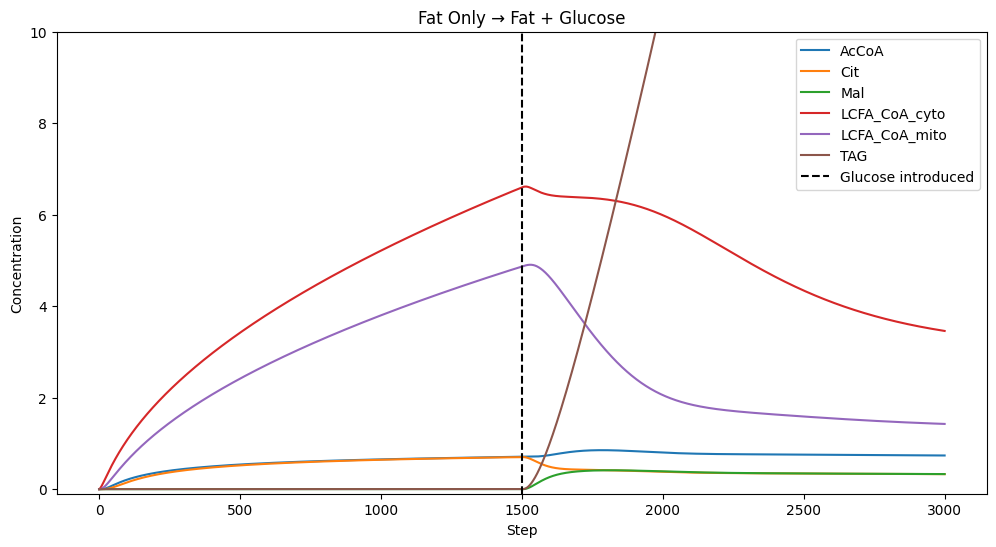

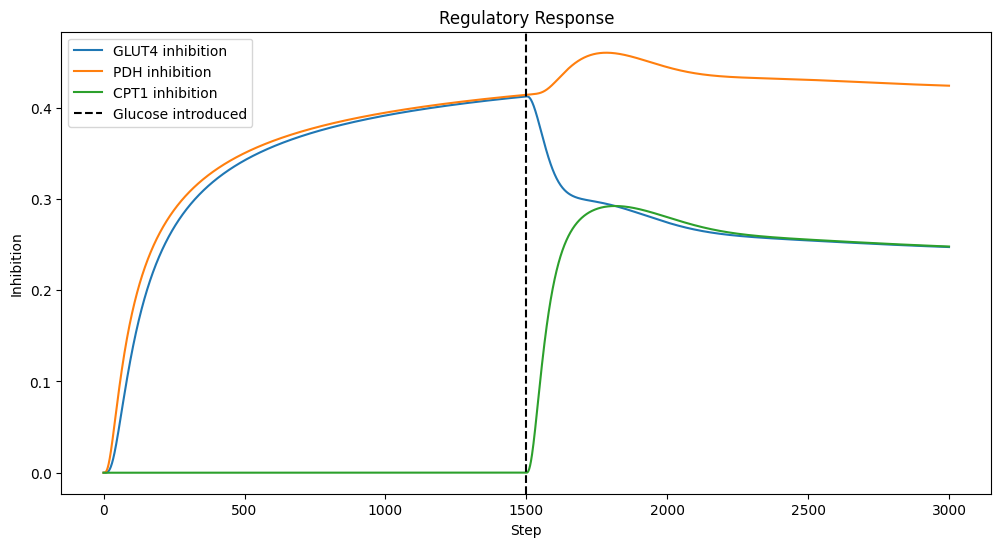

In [20]:
# ------------------------------------------------------------
# Dynamic Test - Glucose Introduction Experiment
#
# Purpose:
# Start with fat as the only fuel source.
# Then introduce glucose midway through the simulation.
#
# Questions:
# - Does citrate increase after glucose appears?
# - Does malonyl-CoA increase?
# - Does CPT1 inhibition strengthen?
# - Does TAG synthesis accelerate?
# - Does the system shift from fat oxidation toward storage?
# ------------------------------------------------------------

state = kinetics.DEFAULT_STATE.copy()

history = []

n_steps = 3000
switch_step = 1500

for step in range(n_steps):

    if step < switch_step:

        glu_in = 0.0
        fat_in = 1.0
        atp_draw = 1.0

    else:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 1.0

    state, flux = step_ivp_once(
        state,
        glu_in=glu_in,
        fat_in=fat_in,
        atp_draw=atp_draw
    )

    history.append(state.copy())

history = np.array(history)

plt.figure(figsize=(12, 6))

for metabolite in [
    "AcCoA",
    "Cit",
    "Mal",
    "LCFA_CoA_cyto",
    "LCFA_CoA_mito",
    "TAG"
]:
    plt.plot(
        history[:, kinetics.STATE_INDEX[metabolite]],
        label=metabolite
    )

plt.axvline(
    switch_step,
    color="black",
    linestyle="--",
    label="Glucose introduced"
)

plt.title("Fat Only → Fat + Glucose")
plt.xlabel("Step")
plt.ylabel("Concentration")
plt.ylim(-0.1, 10)
plt.legend()
plt.show()



# Track inhibition dynamics

state = kinetics.DEFAULT_STATE.copy()

inh_glut = []
inh_pdh = []
inh_cpt1 = []
#inh_pfk = []

for step in range(n_steps):

    if step < switch_step:

        glu_in = 0.0
        fat_in = 1.0
        atp_draw = 1.0

    else:

        glu_in = 1.0
        fat_in = 1.0
        atp_draw = 1.0

    state, flux = step_ivp_once(
        state,
        glu_in=glu_in,
        fat_in=fat_in,
        atp_draw=atp_draw
    )

    inhib = kinetics.compute_inhibitions(state)
    
    inh_glut.append(inhib["GLUT4"])
    inh_pdh.append(inhib["PDH"])
    inh_cpt1.append(inhib["CPT1"])
    #inh_pfk.append(inhib["PFK"])

plt.figure(figsize=(12, 6))

plt.plot(inh_glut, label="GLUT4 inhibition")
plt.plot(inh_pdh, label="PDH inhibition")
plt.plot(inh_cpt1, label="CPT1 inhibition")
#plt.plot(inh_pfk, label="PFK inhibition")

plt.axvline(
    switch_step,
    color="black",
    linestyle="--",
    label="Glucose introduced"
)

plt.title("Regulatory Response")
plt.xlabel("Step")
plt.ylabel("Inhibition")
plt.legend()
plt.show()